#### Importing Modules

In [188]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import random
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix)
import tensorflow as tf
import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout
from tensorflow.keras.metrics import Precision,Recall,F1Score
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint

#### Making randomization reproducible

In [189]:
SEED=42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

#### Reading data

In [190]:
df=pd.read_csv("diabetes_dataset_with_notes.csv")
df.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0,"Overweight, advised dietary and exercise modif..."
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0,Healthy BMI range.
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0,"Young patient, generally lower risk but needs ..."
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0,"Overweight, advised dietary and exercise modif..."
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0,"Healthy BMI range. High HbA1c level, indicativ..."


In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [192]:
df.describe()#numeric cols only

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [193]:
df.describe(include='object')#categorical cols only

,gender,location,smoking_history,clinical_notes
count,100000,100000,100000,100000
unique,3,55,6,761
top,Female,Kentucky,No Info,"Overweight, advised dietary and exercise modif..."
freq,58552,2038,35816,4650


#### Checking for missing values

In [194]:
df.isnull().sum()

year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
clinical_notes          0
dtype: int64

#### Checking for duplicated rows

In [195]:
df.duplicated().sum()

np.int64(14)

In [196]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

#### Checking for incorrect values

In [197]:
df['gender'].value_counts()

gender
Female    58546
Male      41422
Other        18
Name: count, dtype: int64

dropping 'Other' values in gender as they are incorrect

In [198]:
df=df[df['gender']!='Other']
df['gender'].value_counts()

gender
Female    58546
Male      41422
Name: count, dtype: int64

hbA1c_level Invalid Values: Below 0 or above 100.

In [199]:
df[df['hbA1c_level']<0]

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes


In [200]:
df[df['hbA1c_level']>100]

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes


In [201]:
df[df['bmi']<0]

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes


In [202]:
df[df['blood_glucose_level']<0]

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes,clinical_notes


#### Dropping unnecessary columns

year and clinical notes are not important in our prediction

In [203]:
df.drop(['year','clinical_notes'],axis=1,inplace=True)

#### Checking Target Column Distribution

Text(0.5, 1.0, 'Diabetes Count Distribution')

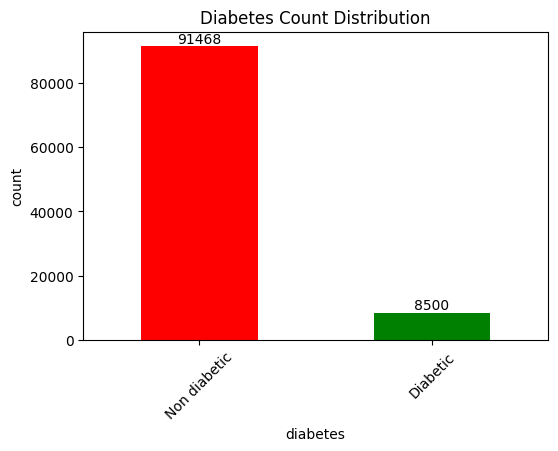

In [204]:
plt.figure(figsize=(6,4))
ax=df['diabetes'].value_counts().plot(kind='bar',color=['red','green'])
plt.xlabel('diabetes')
plt.ylabel('count')
plt.xticks(rotation=45,ticks=[0,1],labels=['Non diabetic','Diabetic'])
ax.bar_label(ax.containers[0]) #adding exact count above the bar
plt.title("Diabetes Count Distribution")

Data is heavily imbalanced, which is expected in disease detection data

#### Checking features distribution

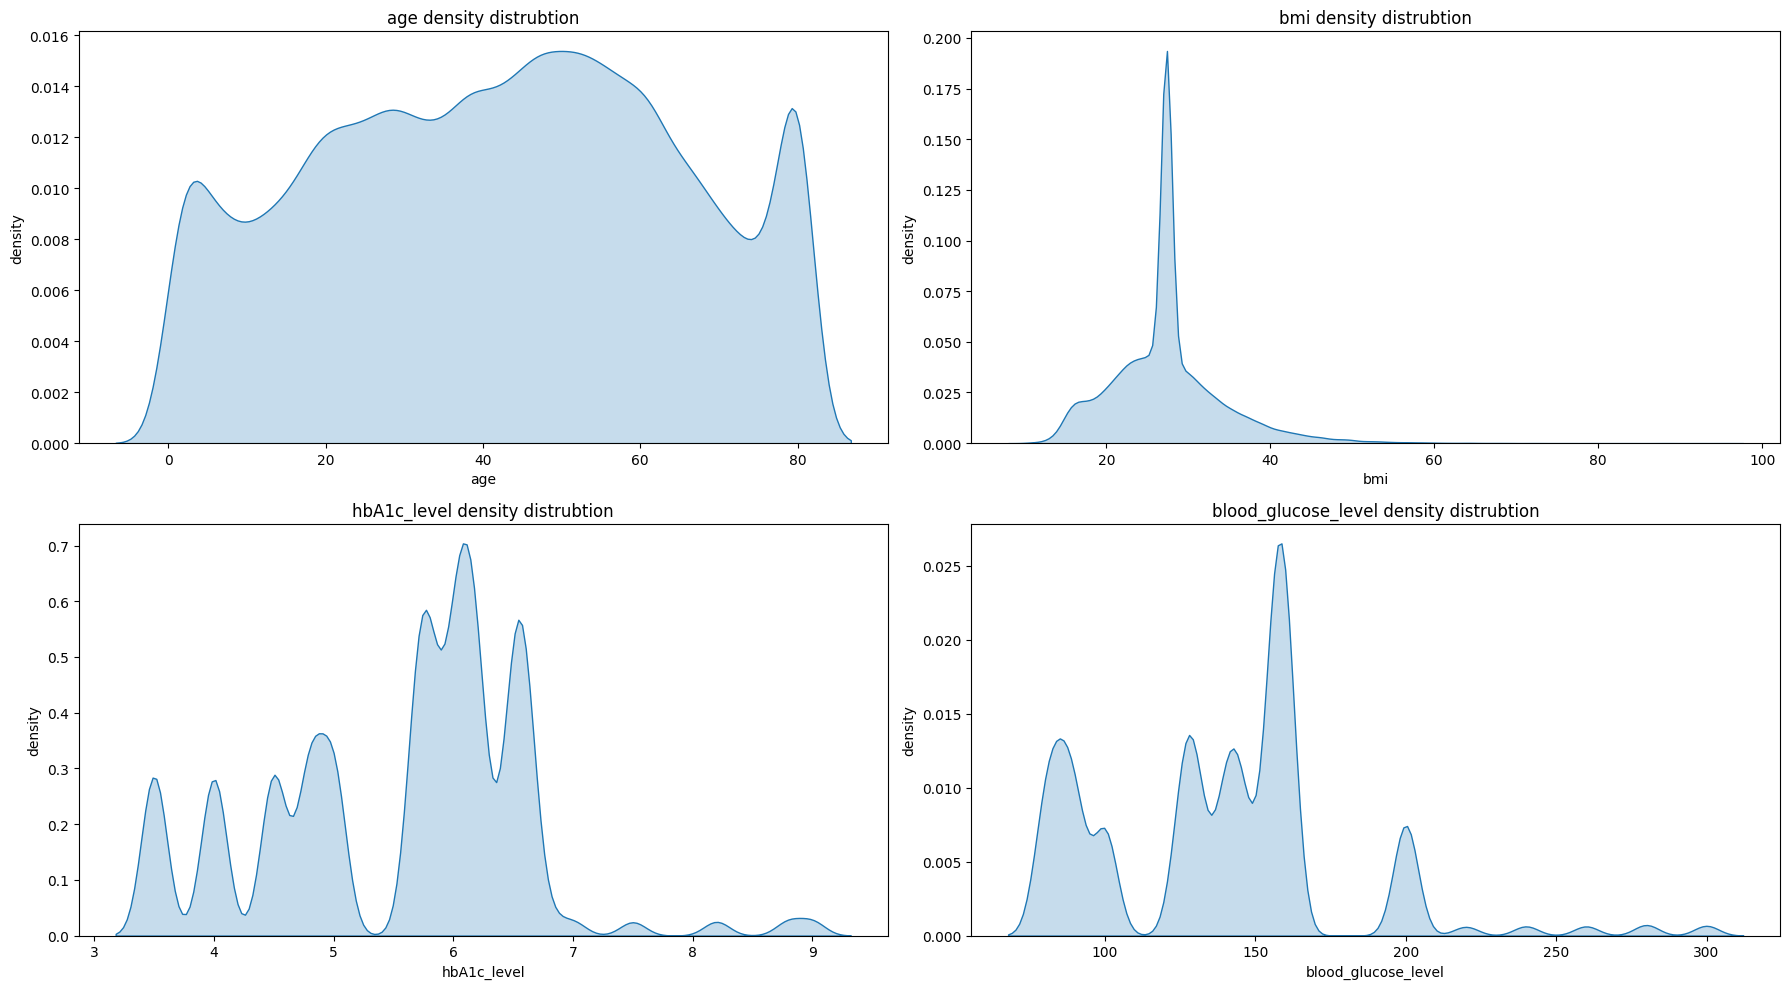

In [205]:
numerical=['age','bmi','hbA1c_level','blood_glucose_level']
plt.figure(figsize=(18,10))
for i,col in enumerate(numerical):
    plt.subplot(2,2,i+1)
    sns.kdeplot(data=df,x=col,fill=True)
    plt.xlabel(col)
    plt.ylabel('density')
    plt.title(f"{col} density distrubtion")

plt.tight_layout()
plt.show()

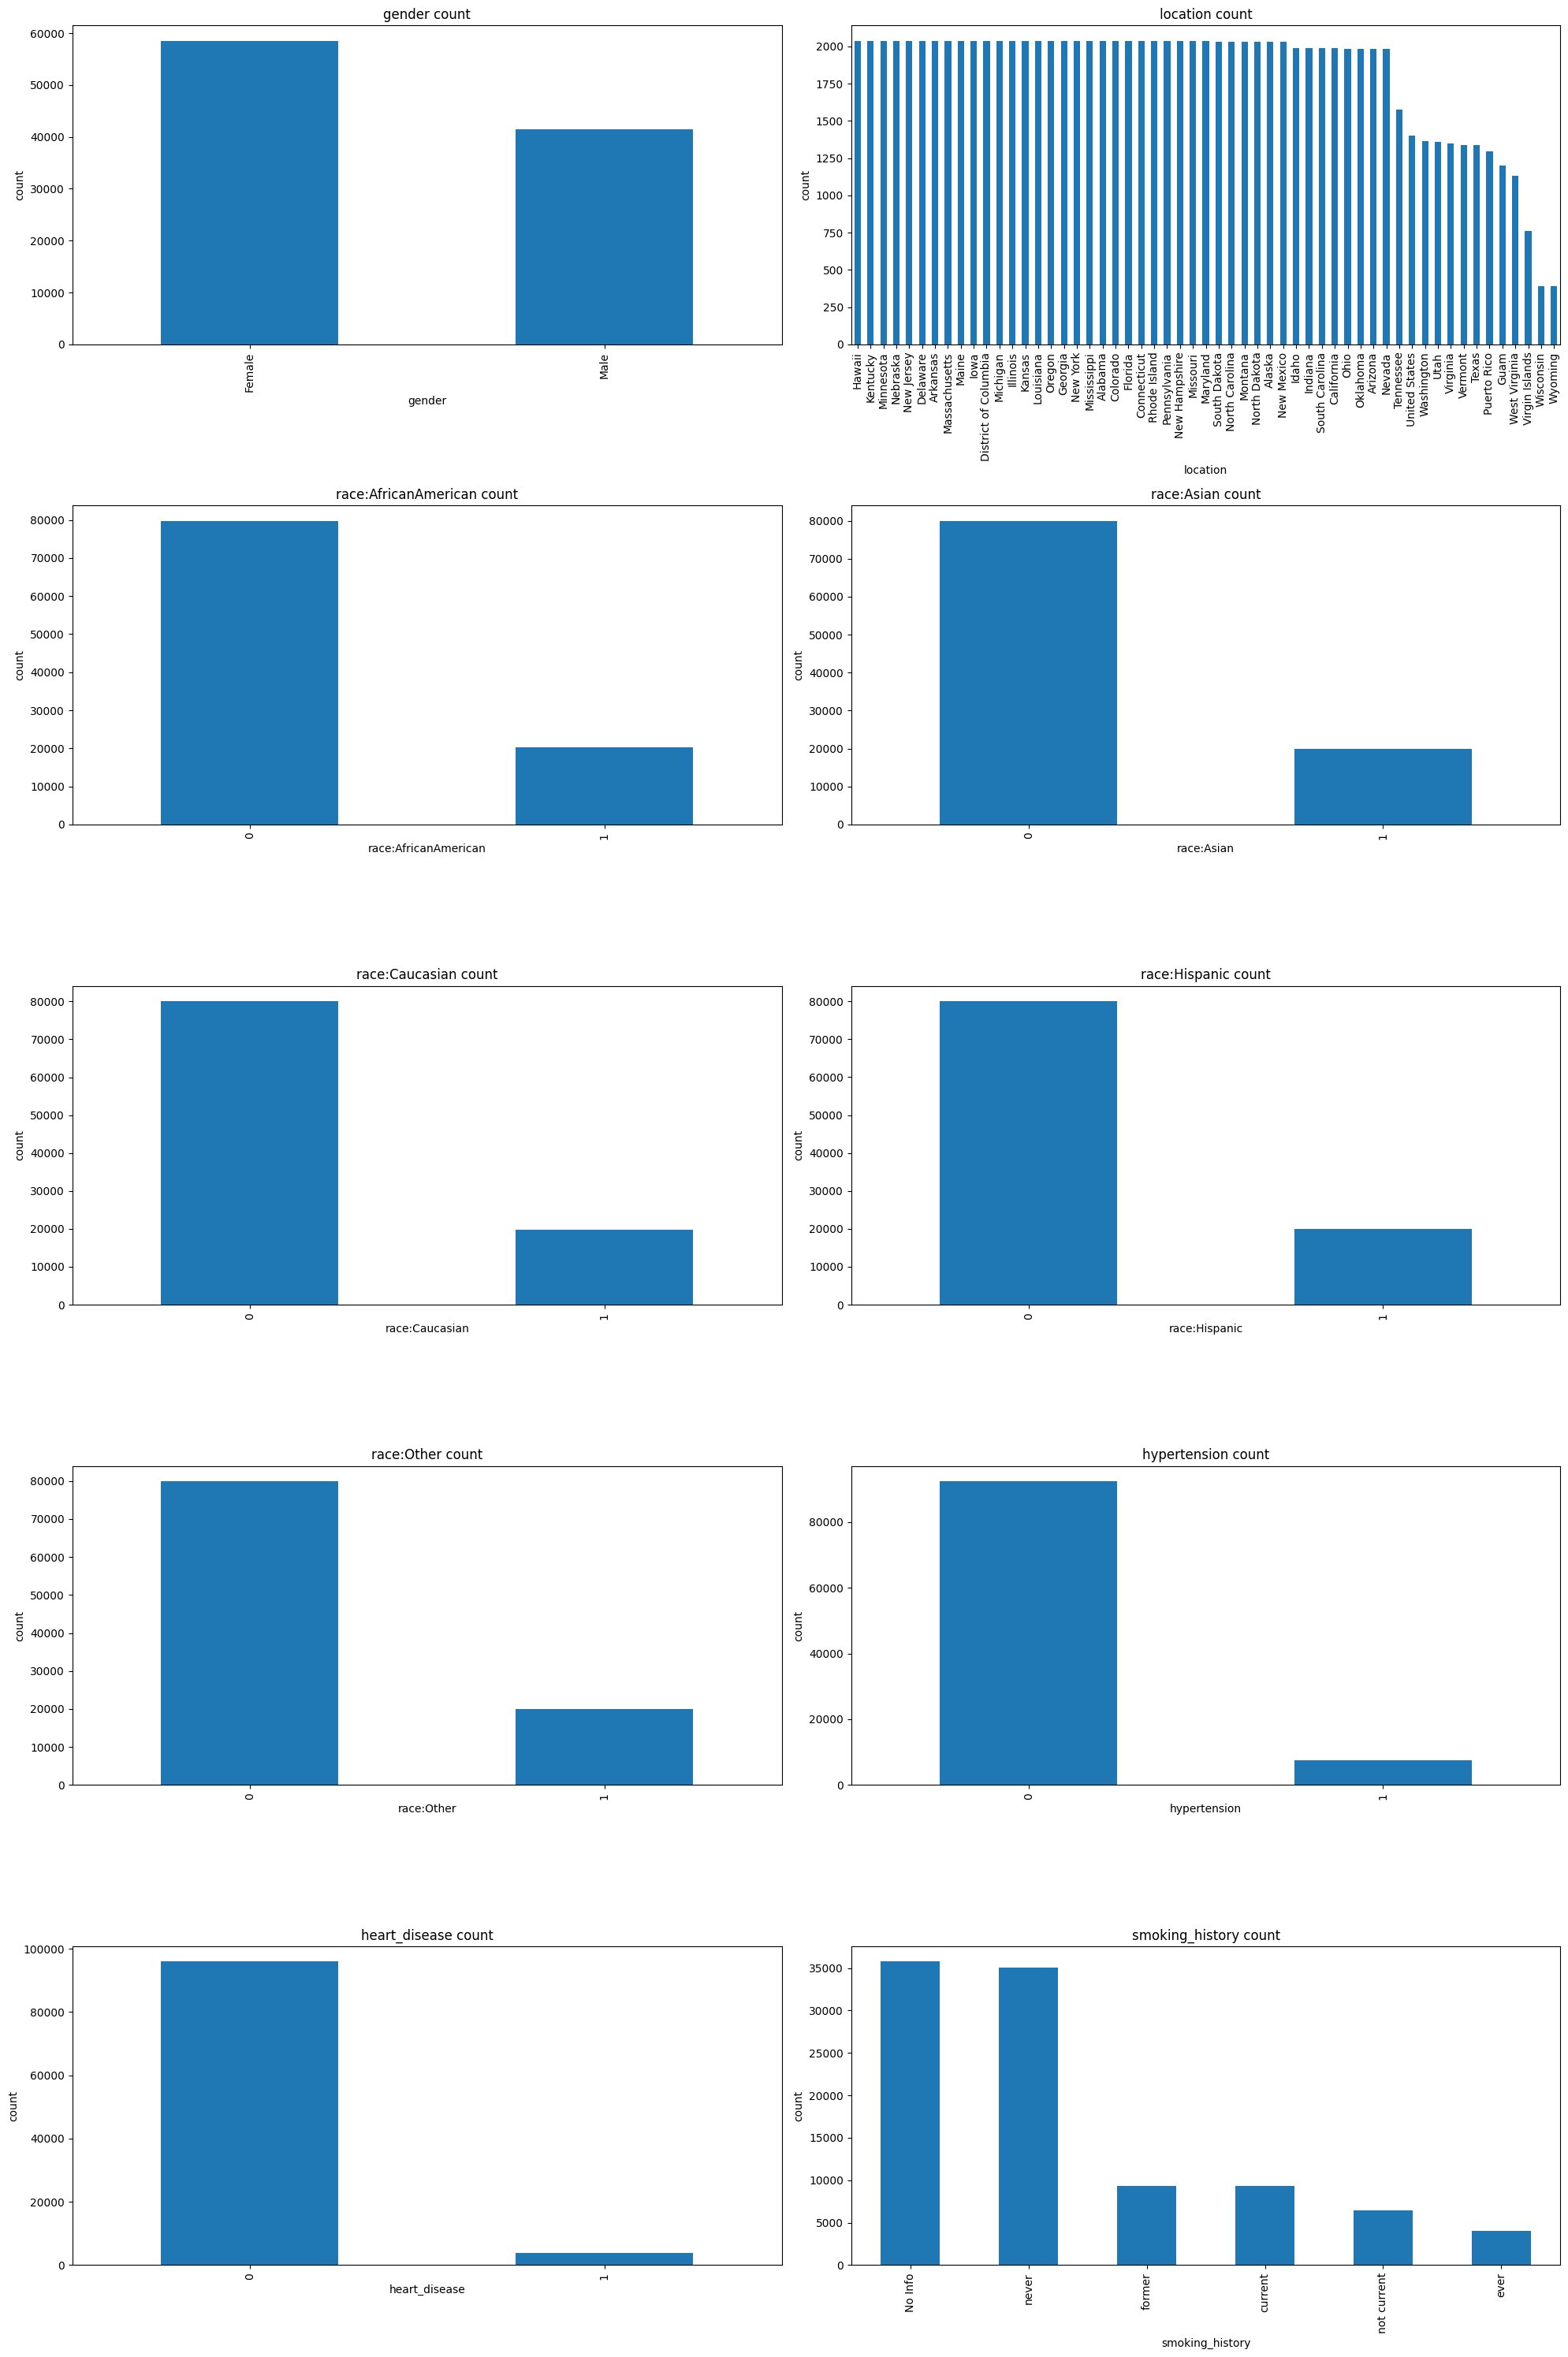

In [206]:
categorical=['gender','location','race:AfricanAmerican','race:Asian','race:Caucasian','race:Hispanic','race:Other','hypertension','heart_disease','smoking_history']
plt.figure(figsize=(20,30))
for i,col in enumerate(categorical):
    plt.subplot(5,2,i+1)
    df[col].value_counts().plot(kind='bar')
    plt.xlabel(col)
    plt.ylabel('count')
    plt.title(f"{col} count")

plt.tight_layout()
plt.show()

#### Checking for outliers

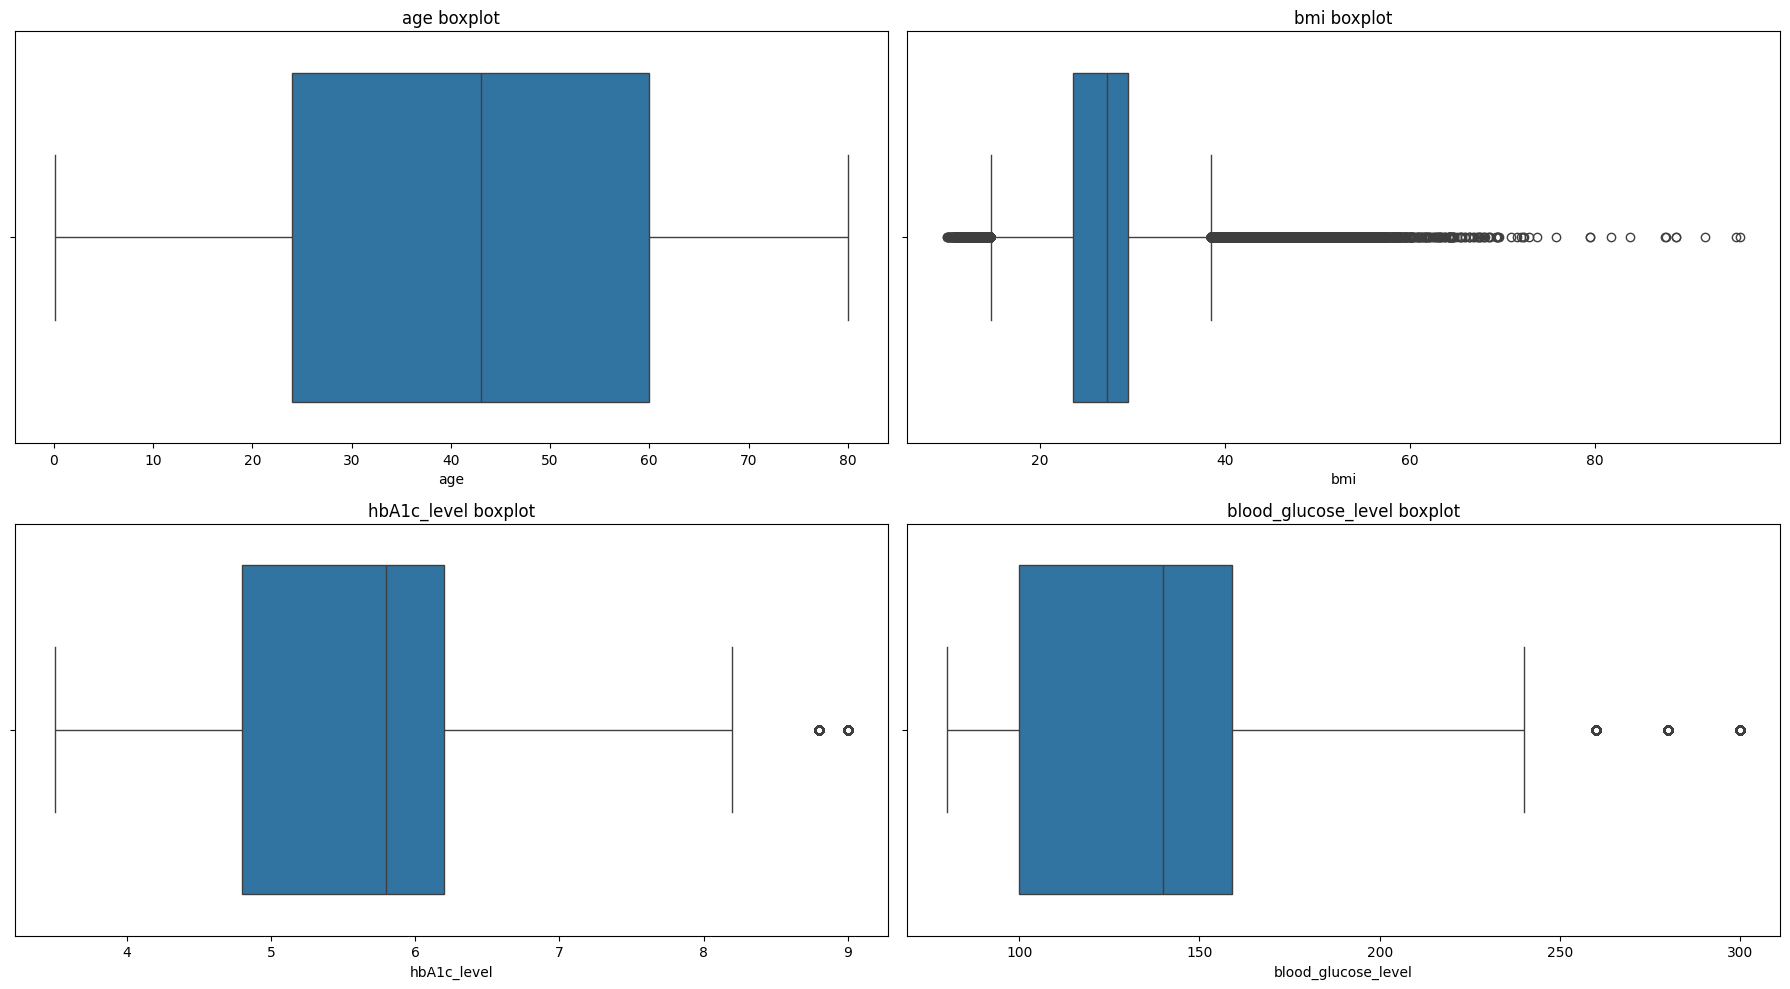

In [207]:
numerical=['age','bmi','hbA1c_level','blood_glucose_level']
plt.figure(figsize=(18,10))
for i,col in enumerate(numerical):
    plt.subplot(2,2,i+1)
    sns.boxplot(data=df,x=col)
    plt.title(f"{col} boxplot")

plt.tight_layout()
plt.show()

bmi has a lot of outliers
hbA1c_level and blood_glucose_level have outliers

#### Splitting X and Y

In [208]:
X=df.drop(['diabetes'],axis=1)
y=df['diabetes']
X.head()

,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level
0,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100
1,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90
2,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160
3,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159
4,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90


In [209]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: diabetes, dtype: int64

#### Splitting data

splitting to 70% train, 15% val and 15% test

In [210]:
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=0.3,shuffle=True,stratify=y,random_state=SEED)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=0.5,shuffle=True,stratify=y_temp,random_state=SEED)

#### Encoding Labels

One hot encoding for gender and smoking_history\
Label Encoding for location

In [211]:
le=LabelEncoder()
X_train['location']=le.fit_transform(X_train['location'])
X_val['location']=le.transform(X_val['location'])
X_test['location']=le.transform(X_test['location'])
df.head()

,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [212]:
X_train=pd.get_dummies(X_train,columns=['gender','smoking_history'],dtype=int,drop_first=True)
X_val=pd.get_dummies(X_val,columns=['gender','smoking_history'],dtype=int,drop_first=True)
X_test=pd.get_dummies(X_test,columns=['gender','smoking_history'],dtype=int,drop_first=True)

In [213]:
X_train.head()

,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,gender_Male,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
10361,49.0,5,0,0,1,0,0,0,0,49.97,3.5,80,0,0,0,0,1,0
86945,70.0,43,0,1,0,0,0,0,0,27.32,6.0,160,0,0,0,0,0,0
26668,73.0,13,0,0,0,1,0,0,0,24.41,6.1,159,0,0,0,0,1,0
85448,57.0,42,0,0,1,0,0,1,1,21.68,4.0,158,0,1,0,0,0,0
16497,26.0,8,0,0,1,0,0,1,0,32.98,4.0,126,1,0,0,0,1,0


#### Checking shape of data to ensure no different columns in train than val and test

In [214]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)
print(X_train.columns.equals(X_val.columns))
print(X_train.columns.equals(X_test.columns))

(69977, 18)
(14995, 18)
(14996, 18)
True
True


#### Feature Scaling

StandardScaler automatically scales each column independently using its own mean and standard deviation

In [215]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_val=scaler.transform(X_val)
X_test=scaler.transform(X_test)

#### Computing class weights

In [216]:
classes=np.unique(y_train)
weights=compute_class_weight(class_weight='balanced',classes=classes,y=y_train)
weights=dict(zip(classes,weights))
print(weights)

{np.int64(0): np.float64(0.5464647726740282), np.int64(1): np.float64(5.880420168067227)}


#### ANN Model

We are binary classification so:\
loss function is binary cross entropy\
output layer has 1 neuron only\
output layer activation function is sigmoid

In [217]:
model=Sequential([
    Dense(256,activation='relu',input_shape=(X_train.shape[1],)),
    Dropout(0.4),
    Dense(128,activation='relu'),
    Dropout(0.4),
    Dense(64,activation='relu'),
    Dropout(0.3),
    Dense(1,activation='sigmoid'),
])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_23 (Dense)                │ (None, 256)            │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,081 (180.00 KB)

 Trainable params: 46,081 (180.00 KB)

 Non-trainable params: 0 (0.00 B)

#### Adding early stopping

In [218]:
early_stopping=EarlyStopping(monitor='val_loss',patience=5,verbose=0,min_delta=0.001,mode='min',restore_best_weights=True)

#### Adding model checkpoint

In [219]:
model_checkpoint=ModelCheckpoint('best_model.keras',monitor='val_loss',save_best_only=True,mode='min')

In [220]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy',keras.metrics.Precision(name='precision'),keras.metrics.Recall(name='recall'),keras.metrics.AUC(name='auc')])

In [221]:
model.fit(X_train,y_train,validation_data=(X_val,y_val),class_weight=weights,batch_size=64,callbacks=[early_stopping,model_checkpoint],epochs=50,verbose=1,shuffle=False)

Epoch 1/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8575 - auc: 0.9477 - loss: 0.2901 - precision: 0.3610 - recall: 0.8768 - val_accuracy: 0.8858 - val_auc: 0.9608 - val_loss: 0.2204 - val_precision: 0.4187 - val_recall: 0.8847
Epoch 2/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8711 - auc: 0.9598 - loss: 0.2538 - precision: 0.3885 - recall: 0.8995 - val_accuracy: 0.8675 - val_auc: 0.9646 - val_loss: 0.2395 - val_precision: 0.3830 - val_recall: 0.9145
Epoch 3/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8764 - auc: 0.9652 - loss: 0.2338 - precision: 0.4002 - recall: 0.9087 - val_accuracy: 0.8945 - val_auc: 0.9693 - val_loss: 0.1978 - val_precision: 0.4404 - val_recall: 0.8902
Epoch 4/50
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8818 - auc: 0.9689 - loss: 0.2200 - precision: 0.4120 - recall: 0.9141 - val_accuracy: 0.8856 - val_auc: 0.9727 - val_loss: 0.1978 - val_precision: 0.4206 - val_recall: 0.9145
Epoch 5/50
1094/1094 ━━━

In [222]:
eval=model.evaluate(X_test, y_test,verbose=1)

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9007 - auc: 0.9745 - loss: 0.1740 - precision: 0.4572 - recall: 0.8973


#### Making Predictions

In [223]:
y_prob = model.predict(X_test).flatten()
y_pred = (y_prob >= 0.5).astype(int)

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


#### Evaluation metrics

In [224]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9007068551613764
Precision: 0.4572342126298961
Recall: 0.8972549019607843
F1 Score: 0.6057717765422292
ROC-AUC: 0.9744853959366708


#### Classification Report

In [225]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     13721
           1       0.46      0.90      0.61      1275

    accuracy                           0.90     14996
   macro avg       0.72      0.90      0.77     14996
weighted avg       0.94      0.90      0.91     14996



#### Confusion Matrix

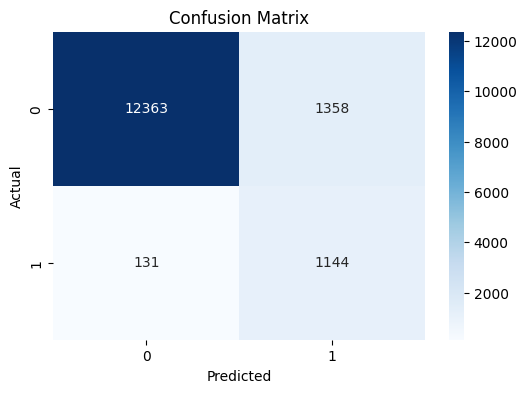

In [226]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()